# Python for Data Science — Implementation Cheatsheet

Theory / quick reference: [python_pandas_numpy.md](python_pandas_numpy.md)

The everyday toolkit: **NumPy** (arrays & math), **pandas** (tables), **matplotlib / seaborn** (plots).
Examples use the SuperKart dataset from [regression](../03_regression/regression.ipynb).

| # | Section |
|---|---|
| 1 | NumPy |
| 2 | pandas: load & inspect |
| 3 | pandas: select & filter |
| 4 | pandas: create & transform columns |
| 5 | pandas: group, pivot, merge |
| 6 | Visualization (the Plot Guide) |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", None)

## 1. NumPy

In [2]:
a = np.array([1, 2, 3, 4, 5])
m = np.arange(12).reshape(3, 4)          # 3 rows x 4 cols
print(a.dtype, a.shape, m.shape, m.ndim)

# Vectorized math: no loops
print(a * 10, a ** 2, np.sqrt(a))

# Aggregations, axis=0 -> down the rows (per column), axis=1 -> across columns (per row)
print(m.sum(), m.sum(axis=0), m.sum(axis=1))
print(a.mean(), np.median(a), a.std(), a.min(), a.argmax())

int64 (5,) (3, 4) 2
[10 20 30 40 50] [ 1  4  9 16 25] [1.         1.41421356 1.73205081 2.         2.23606798]
66 [12 15 18 21] [ 6 22 38]
3.0 3.0 1.4142135623730951 1 4


In [3]:
# Indexing, slicing, boolean masks
print(m[0, 1], m[:, 0], m[1:, 2:])
print(a[a > 2])                          # boolean mask
print(np.where(a > 2, "big", "small"))   # vectorized if/else

# Broadcasting: shapes (3,4) and (4,) combine
print(m - m.mean(axis=0))

# Random numbers (always fix the seed for reproducibility)
rng = np.random.default_rng(42)
print(rng.normal(loc=0, scale=1, size=3), rng.integers(0, 10, size=5), rng.choice(["a", "b"], size=4))

# Linear algebra
A = np.array([[2, 1], [1, 3]]); b = np.array([3, 5])
print(A @ A, A.T, np.linalg.inv(A), np.linalg.solve(A, b))

1 [0 4 8] [[ 6  7]
 [10 11]]
[3 4 5]
['small' 'small' 'big' 'big' 'big']
[[-4. -4. -4. -4.]
 [ 0.  0.  0.  0.]
 [ 4.  4.  4.  4.]]
[ 0.30471708 -1.03998411  0.7504512 ] [0 6 2 0 5] ['b' 'b' 'b' 'b']
[[ 5  5]
 [ 5 10]] [[2 1]
 [1 3]] [[ 0.6 -0.2]
 [-0.2  0.4]] [0.8 1.4]


## 2. pandas: load & inspect

In [4]:
df = pd.read_csv("../data/superkart.csv")       # also: pd.read_excel, pd.read_parquet, sep="\t"
df.head(3)

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16


In [5]:
print(df.shape)
df.info()

(8763, 12)
<class 'pandas.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   str    
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   str    
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   str    
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   str    
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   str    
 9   Store_Location_City_Type   8763 non-null   str    
 10  Store_Type                 8763 non-null   str    
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 821.7 KB


In [6]:
df.describe().T                                 # numeric summary

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


In [7]:
df.describe(include=["object", "string"]).T     # categorical summary (count, unique, top, freq)

,count,unique,top,freq
Product_Id,8763,8763,FD6114,1
Product_Sugar_Content,8763,4,Low Sugar,4885
Product_Type,8763,16,Fruits and Vegetables,1249
Store_Id,8763,4,OUT004,4676
Store_Size,8763,3,Medium,6025
Store_Location_City_Type,8763,3,Tier 2,6262
Store_Type,8763,4,Supermarket Type2,4676


In [8]:
print(df["Store_Type"].value_counts())                  # counts
print(df["Store_Type"].value_counts(normalize=True))    # proportions
print(df.isna().sum().sum(), "missing |", df.duplicated().sum(), "duplicates |", df["Product_Id"].nunique(), "unique ids")

Store_Type
Supermarket Type2     4676
Supermarket Type1     1586
Departmental Store    1349
Food Mart             1152
Name: count, dtype: int64
Store_Type
Supermarket Type2     0.533607
Supermarket Type1     0.180988
Departmental Store    0.153943
Food Mart             0.131462
Name: proportion, dtype: float64
0 missing | 0 duplicates | 8763 unique ids


## 3. pandas: select & filter

In [9]:
df["Product_MRP"]                    # one column -> Series
df[["Product_MRP", "Store_Type"]]    # several -> DataFrame
df.loc[0:2, ["Product_MRP", "Store_Type"]]   # loc = by LABEL (end included)
df.iloc[0:2, 0:3]                            # iloc = by POSITION (end excluded)

,Product_Id,Product_Weight,Product_Sugar_Content
0,FD6114,12.66,Low Sugar
1,FD7839,16.54,Low Sugar


In [10]:
# Boolean filtering: & (and), | (or), ~ (not), each condition in parentheses
df[(df["Store_Type"] == "Food Mart") & (df["Product_MRP"] > 150)].head(3)

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
130,FD451,14.42,Regular,0.036,Dairy,162.86,OUT002,1998,Small,Tier 3,Food Mart,913.54
227,FD292,11.76,Regular,0.093,Canned,169.01,OUT002,1998,Small,Tier 3,Food Mart,536.20
266,FD318,12.96,Low Sugar,0.034,Fruits and Vegetables,179.75,OUT002,1998,Small,Tier 3,Food Mart,1892.93


In [11]:
df[df["Product_Type"].isin(["Dairy", "Meat"])].shape, df.query("Product_MRP > 200 and Store_Size == 'High'").shape

((1414, 12), (71, 12))

## 4. pandas: create & transform columns

In [12]:
d = df.copy()                                    # work on a copy
d["Store_Age"] = 2023 - d["Store_Establishment_Year"]                     # arithmetic
d["Product_Prefix"] = d["Product_Id"].str[:2]                             # string methods (.str)
d["Sugar"] = d["Product_Sugar_Content"].replace({"reg": "Regular"})       # replace values
d["Price_Band"] = pd.cut(d["Product_MRP"], bins=[0, 100, 150, 200, 300],
                         labels=["low", "mid", "high", "premium"])        # numeric -> bins
d["Is_Perishable"] = d["Product_Type"].isin(["Dairy", "Meat", "Breads", "Seafood"]).astype(int)
d["Sales_k"] = d["Product_Store_Sales_Total"].apply(lambda x: round(x / 1000, 1))   # apply (slower, flexible)
d = d.rename(columns={"Product_MRP": "MRP"}).drop(columns=["Store_Establishment_Year"])
d.sort_values("MRP", ascending=False).head(3)

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,MRP,Store_Id,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,Store_Age,Product_Prefix,Sugar,Price_Band,Is_Perishable,Sales_k
4356,NC7325,22.00,No Sugar,0.060,Household,266.00,OUT003,Medium,Tier 1,Departmental Store,8000.00,24,NC,No Sugar,premium,0,8.0
3020,FD5995,15.23,Regular,0.067,Fruits and Vegetables,254.34,OUT003,Medium,Tier 1,Departmental Store,6231.41,24,FD,Regular,premium,0,6.2
8138,FD8746,17.81,Low Sugar,0.027,Starchy Foods,250.57,OUT003,Medium,Tier 1,Departmental Store,6736.81,24,FD,Low Sugar,premium,0,6.7


In [13]:
# Dates
dates = pd.to_datetime(pd.Series(["04-09-2012", "08-03-2014"]), format="%d-%m-%Y")
pd.DataFrame({"date": dates, "year": dates.dt.year, "month": dates.dt.month, "weekday": dates.dt.day_name()})

,date,year,month,weekday
0,2012-09-04,2012,9,Tuesday
1,2014-03-08,2014,3,Saturday


## 5. pandas: group, pivot, merge

In [14]:
# groupby + agg: the pandas version of SQL GROUP BY
(df.groupby("Store_Type")
   .agg(n_products=("Product_Id", "count"),
        total_sales=("Product_Store_Sales_Total", "sum"),
        avg_mrp=("Product_MRP", "mean"))
   .sort_values("total_sales", ascending=False)
   .round(1))

,n_products,total_sales,avg_mrp
Store_Type,,,
Supermarket Type2,4676,15427583.4,142.4
Departmental Store,1349,6673457.6,181.4
Supermarket Type1,1586,6223113.2,160.5
Food Mart,1152,2030909.7,107.1


In [15]:
# pivot_table: Excel pivot
pd.pivot_table(df, index="Store_Type", columns="Store_Location_City_Type",
               values="Product_Store_Sales_Total", aggfunc="mean").round(0)

Store_Location_City_Type,Tier 1,Tier 2,Tier 3
Store_Type,,,
Departmental Store,4947.0,NaN,NaN
Food Mart,NaN,NaN,1763.0
Supermarket Type1,NaN,3924.0,NaN
Supermarket Type2,NaN,3299.0,NaN


In [16]:
# crosstab: counts (or % with normalize) of two categoricals
pd.crosstab(df["Store_Size"], df["Product_Sugar_Content"], normalize="index").round(2)

Product_Sugar_Content,Low Sugar,No Sugar,Regular,reg
Store_Size,,,,
High,0.53,0.18,0.28,0.01
Medium,0.56,0.17,0.25,0.01
Small,0.57,0.18,0.24,0.01


In [17]:
# merge = SQL JOIN (how="left" | "inner" | "right" | "outer"); concat = stack tables
stores = df.groupby("Store_Id", as_index=False)["Product_Store_Sales_Total"].sum()
targets = pd.DataFrame({"Store_Id": ["OUT001", "OUT002", "OUT003", "OUT004"], "target": [6e6, 2e6, 7e6, 15e6]})
merged = stores.merge(targets, on="Store_Id", how="left")
merged["hit_target"] = merged["Product_Store_Sales_Total"] >= merged["target"]
merged

,Store_Id,Product_Store_Sales_Total,target,hit_target
0,OUT001,6223113.18,6000000.0,True
1,OUT002,2030909.72,2000000.0,True
2,OUT003,6673457.57,7000000.0,False
3,OUT004,15427583.43,15000000.0,True


## 6. Visualization: the Plot Guide

| Plot | Shows | Variables |
|---|---|---|
| `histplot` | distribution (shape, skew, modes) | 1 numeric |
| `boxplot` | median, IQR, outliers; compare groups | 1 numeric (+1 categorical) |
| `countplot` | **count** per category | 1 categorical |
| `barplot` | **mean** per category (+ 95% CI, `errorbar=None` to hide) | categorical + numeric |
| `scatterplot` | relation between 2 numerics | 2 numeric (+hue) |
| `lineplot` | trend over an ordered variable / time | 2 |
| `violinplot` | boxplot + density shape | numeric by category |
| `heatmap` | matrix (correlation, confusion) | many |
| `pairplot` | all pairwise scatterplots + distributions | many numeric |

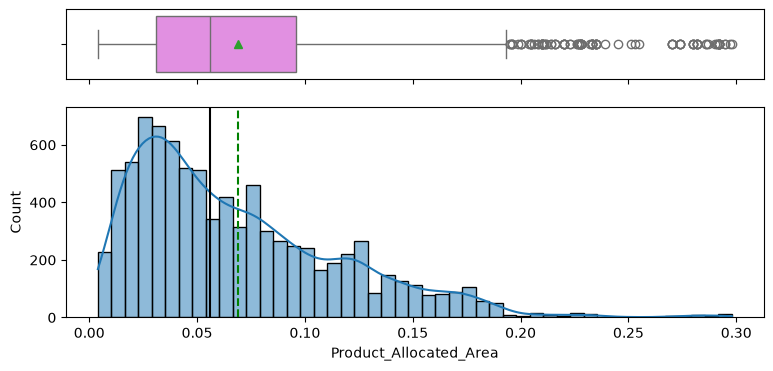

In [18]:
def histogram_boxplot(data, feature, bins=None):
    """The course's favorite helper: boxplot on top, histogram below, with mean (green) and median (black)."""
    fig, (ax_box, ax_hist) = plt.subplots(2, 1, sharex=True, figsize=(9, 4), gridspec_kw={"height_ratios": (1, 3)})
    sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color="violet")
    sns.histplot(data=data, x=feature, kde=True, ax=ax_hist, bins=bins or "auto")
    ax_hist.axvline(data[feature].mean(), color="green", linestyle="--")
    ax_hist.axvline(data[feature].median(), color="black", linestyle="-")
    plt.show()

histogram_boxplot(df, "Product_Allocated_Area")    # right-skewed: mean > median

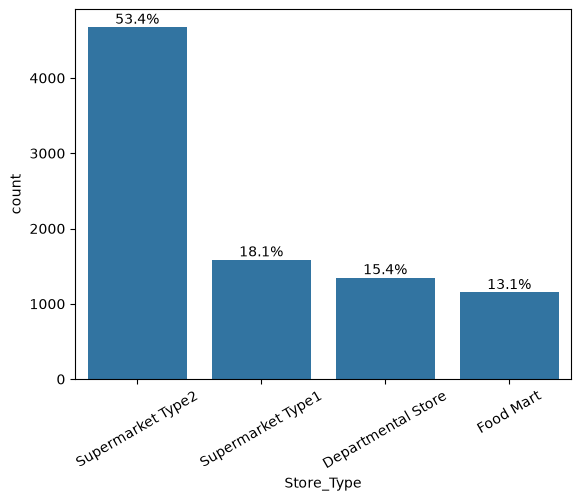

In [19]:
def labeled_barplot(data, feature, perc=False):
    """Countplot with the count (or %) on top of each bar."""
    ax = sns.countplot(data=data, x=feature, order=data[feature].value_counts().index)
    total = len(data)
    for p in ax.patches:
        label = f"{100 * p.get_height() / total:.1f}%" if perc else int(p.get_height())
        ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
    plt.xticks(rotation=30); plt.show()

labeled_barplot(df, "Store_Type", perc=True)

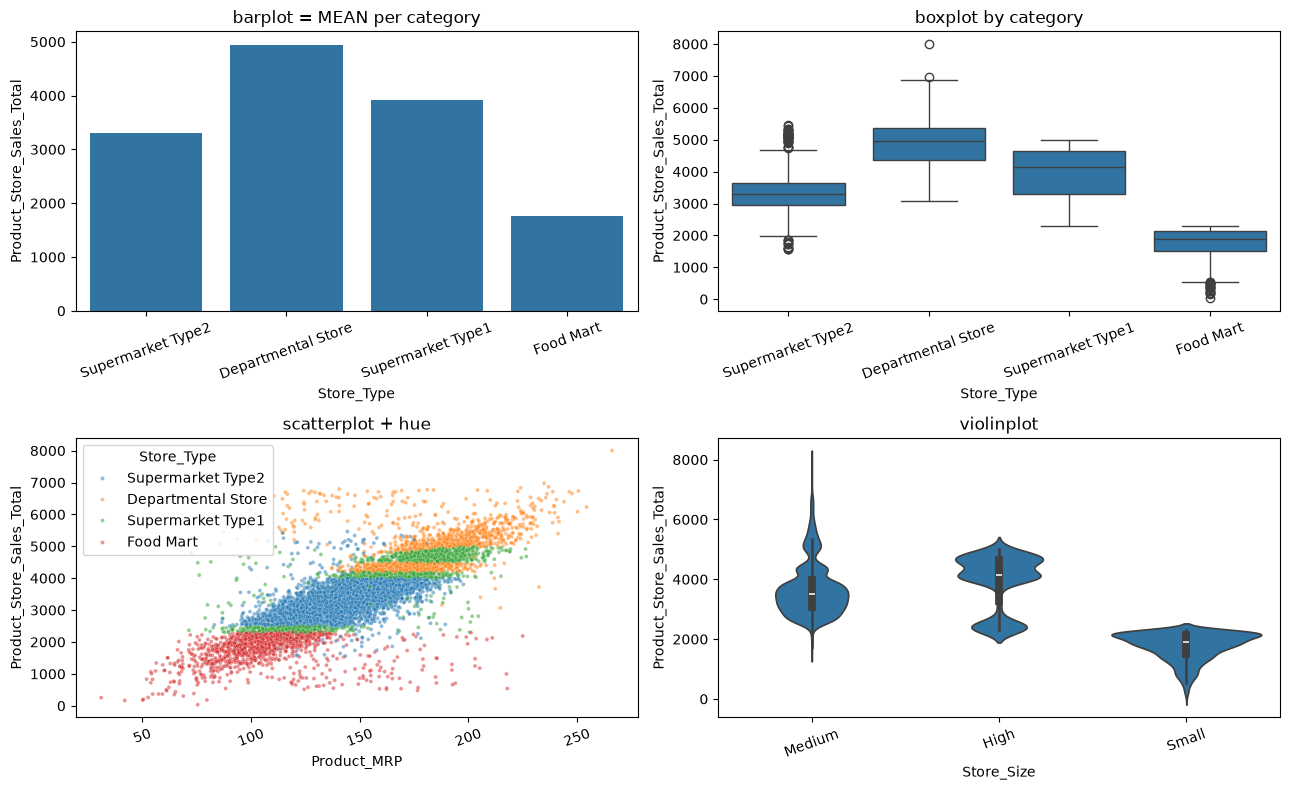

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
sns.barplot(data=df, x="Store_Type", y="Product_Store_Sales_Total", errorbar=None, ax=ax[0, 0]).set_title("barplot = MEAN per category")
sns.boxplot(data=df, x="Store_Type", y="Product_Store_Sales_Total", ax=ax[0, 1]).set_title("boxplot by category")
sns.scatterplot(data=df, x="Product_MRP", y="Product_Store_Sales_Total", hue="Store_Type", s=8, alpha=.5, ax=ax[1, 0]).set_title("scatterplot + hue")
sns.violinplot(data=df, x="Store_Size", y="Product_Store_Sales_Total", ax=ax[1, 1]).set_title("violinplot")
for a in ax.ravel(): a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

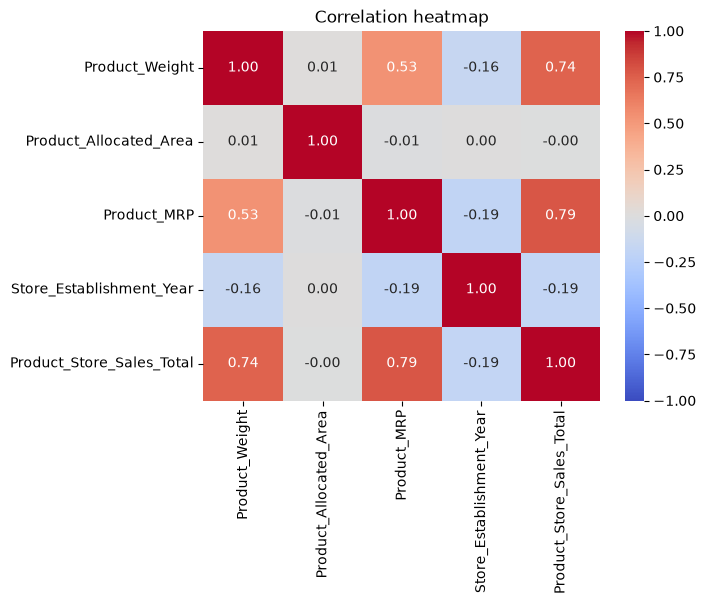

In [21]:
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap"); plt.show()

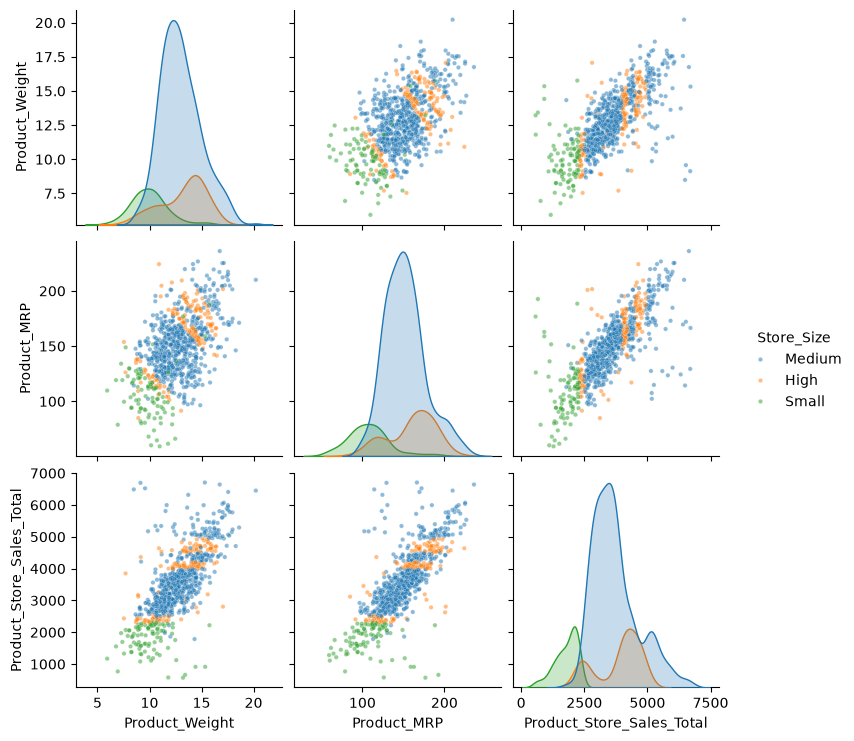

In [22]:
sns.pairplot(df[["Product_Weight", "Product_MRP", "Product_Store_Sales_Total", "Store_Size"]].sample(800, random_state=1),
             hue="Store_Size", plot_kws={"s": 10, "alpha": .5})
plt.show()